# TED 03 - StudyTrack IA | Reprodução técnica local com saídas
**Big Data e Ciências de Dados | ADS 2026.2 | UNIBALSAS**

Este notebook foi **reconstruído para auditoria técnica e executado localmente em 02/11/2026**, a partir do protocolo e da base pública utilizados no notebook da branch de revisão. **Não é uma execução no Google Colab oficial e não substitui o Documento Técnico v3.0 da equipe.**

### Configurações
- Problema: classificação retrospectiva da variável `grade`, com oito classes.
- Entradas: 31 variáveis, sendo 16 nominais e 15 ordinais.
- Treino/teste: estratificado 80/20, `random_state=42`.
- Comparação: Regressão Logística, Árvore de Decisão e Random Forest.
- Validação: `StratifiedKFold` com cinco partes; seleção pelo maior F1-macro médio.
- Teste reservado: utilizado apenas no classificador selecionado pelo critério técnico.

**Fonte primária:** [UCI - Higher Education Students Performance Evaluation](https://doi.org/10.24432/C51G82).  
**Arquivo preparado TED 02:** `data/processed/dataset_modelagem.csv` (Git blob SHA-1 `7859d534e981355b852a520b5e745aac121f9489`).

## 1. Dependências e ambiente de execução

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, confusion_matrix
SEMENTE=42
print('Python:',sys.version.split()[0]); print('pandas:',pd.__version__)
print('NumPy:',np.__version__);print('scikit-learn:',sklearn.__version__)
print('Ambiente: execução técnica local; não é execução no Colab.')

Python: 3.13.5
pandas: 2.2.3
NumPy: 2.3.5
scikit-learn: 1.8.0
Ambiente: execução técnica local; não é execução no Colab.


## 2. Leitura e inspeção da base

In [2]:
# A execução local usa o CSV incluído no pacote. No Colab, o mesmo CSV público é acessado pelo link.
URL_DADOS = ('https://raw.githubusercontent.com/Francisco-alt-coder/'
             'StudyTrack_IA/61d910e73b19f868b9e234cbd92c8756216a53a9/'
             'data/processed/dataset_modelagem.csv')
ARQUIVO_LOCAL = Path('data/processed/dataset_modelagem.csv')
dados = pd.read_csv(ARQUIVO_LOCAL if ARQUIVO_LOCAL.is_file() else URL_DADOS)
assert dados.shape == (145,32), f'Dimensão inesperada: {dados.shape}'
assert 'grade' in dados.columns
X=dados.drop(columns='grade');y=dados['grade']
assert X.shape[1]==31 and set(y.unique())==set(range(8))
print('Dimensão:',dados.shape, '| preditoras:',X.shape[1], '| classes:',y.nunique())
print('Ausentes:',int(dados.isna().sum().sum()),'| duplicados:',int(dados.duplicated().sum()))
display(dados.head(3))

Dimensão: (145, 32) | preditoras: 31 | classes: 8
Ausentes: 0 | duplicados: 0


,idade,sexo,tipo_ensino_medio,tipo_bolsa,trabalho_adicional,atividade_artistica_esportiva,possui_parceiro,faixa_renda,transporte_universidade,tipo_moradia,escolaridade_mae,escolaridade_pai,numero_irmaos,situacao_pais,ocupacao_mae,ocupacao_pai,horas_estudo_semanais,leitura_nao_cientifica,leitura_cientifica,seminarios_conferencias,impacto_projetos_atividades,frequencia_aulas,preparacao_prova_companhia,preparacao_prova_momento,anotacoes_aula,atencao_aula,discussao_interesse_sucesso,sala_invertida,gpa_semestre_anterior,gpa_esperado_formatura,course_id,grade
0,2,2,3,3,1,2,2,1,1,1,1,2,3,1,2,5,3,2,2,1,1,1,1,1,3,2,1,2,1,1,1,1
1,2,2,3,3,1,2,2,1,1,1,2,3,2,1,2,1,2,2,2,1,1,1,1,1,3,2,3,2,2,3,1,1
2,2,2,2,3,2,2,2,2,4,2,2,2,2,1,2,1,2,1,2,1,1,1,1,1,2,2,1,1,2,2,1,1


### 2.1 Frequência das classes

,classe,registros,percentual
0,Fail,8,5.5
1,DD,35,24.1
2,DC,24,16.6
3,CC,21,14.5
4,CB,10,6.9
5,BB,17,11.7
6,BA,13,9.0
7,AA,17,11.7


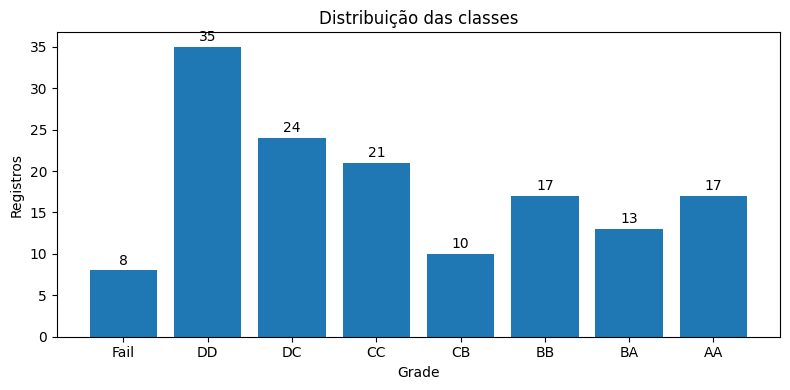

In [3]:
nomes_classes={0:'Fail',1:'DD',2:'DC',3:'CC',4:'CB',5:'BB',6:'BA',7:'AA'}
freq=y.value_counts().sort_index()
display(pd.DataFrame({'classe':[nomes_classes[i] for i in freq.index], 'registros':freq.values,'percentual':np.round(freq.values*100/len(y),1)}))
fig,ax=plt.subplots(figsize=(8,4));b=ax.bar([nomes_classes[i] for i in freq.index],freq.values)
ax.bar_label(b,padding=2);ax.set(title='Distribuição das classes',xlabel='Grade',ylabel='Registros');fig.tight_layout();plt.show()

## 3. Divisão treino/teste estratificada

In [4]:
X_treino,X_teste,y_treino,y_teste=train_test_split(X,y,test_size=0.20,random_state=SEMENTE,stratify=y)
assert len(X_treino)==116 and len(X_teste)==29
assert set(X_treino.index).isdisjoint(set(X_teste.index))
print('Treinamento:',len(X_treino),'| Teste reservado:',len(X_teste))
display(pd.DataFrame({'treino':y_treino.value_counts().sort_index(),'teste':y_teste.value_counts().sort_index()}))

Treinamento: 116 | Teste reservado: 29


,treino,teste
grade,,
0,6,2
1,28,7
2,19,5
3,17,4
4,8,2
5,14,3
6,10,3
7,14,3


## 4. Colunas por tipo e codificação

In [5]:
variaveis_nominais=[
 'sexo','tipo_ensino_medio','trabalho_adicional','atividade_artistica_esportiva',
 'possui_parceiro','transporte_universidade','tipo_moradia','situacao_pais',
 'ocupacao_mae','ocupacao_pai','seminarios_conferencias','impacto_projetos_atividades',
 'preparacao_prova_companhia','preparacao_prova_momento','sala_invertida','course_id']
variaveis_ordinais=[
 'idade','tipo_bolsa','faixa_renda','escolaridade_mae','escolaridade_pai','numero_irmaos',
 'horas_estudo_semanais','leitura_nao_cientifica','leitura_cientifica','frequencia_aulas',
 'anotacoes_aula','atencao_aula','discussao_interesse_sucesso','gpa_semestre_anterior',
 'gpa_esperado_formatura']
assert len(variaveis_nominais)==16 and len(variaveis_ordinais)==15
assert set(variaveis_nominais+variaveis_ordinais)==set(X.columns)
print('16 nominais: One-Hot. 15 ordinais: códigos preservados; padronização na Regressão Logística.')

16 nominais: One-Hot. 15 ordinais: códigos preservados; padronização na Regressão Logística.


## 5. Pipelines independentes

In [6]:
def preproc_linear():
 return ColumnTransformer([
   ('nominais',OneHotEncoder(handle_unknown='ignore',sparse_output=False),variaveis_nominais),
   ('ordinais',StandardScaler(),variaveis_ordinais)])
def preproc_arvores():
 return ColumnTransformer([
   ('nominais',OneHotEncoder(handle_unknown='ignore',sparse_output=False),variaveis_nominais),
   ('ordinais','passthrough',variaveis_ordinais)])
modelos={
 'Regressão Logística':Pipeline([('preprocessamento',preproc_linear()),('classificador',LogisticRegression(max_iter=3000,random_state=SEMENTE))]),
 'Árvore de Decisão':Pipeline([('preprocessamento',preproc_arvores()),('classificador',DecisionTreeClassifier(random_state=SEMENTE))]),
 'Random Forest':Pipeline([('preprocessamento',preproc_arvores()),('classificador',RandomForestClassifier(random_state=SEMENTE,n_jobs=1))])}
print('Modelos:',', '.join(modelos))

Modelos: Regressão Logística, Árvore de Decisão, Random Forest


## 6. Validação cruzada no treinamento

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEMENTE)
linhas=[]
for nome,pipe in modelos.items():
 r=cross_validate(pipe,X_treino,y_treino,cv=cv,scoring={'f1_macro':'f1_macro','acuracia':'accuracy'},return_train_score=True,n_jobs=1,error_score='raise')
 linhas.append({'modelo':nome,'f1_macro_medio':r['test_f1_macro'].mean(),
 'f1_macro_dp':r['test_f1_macro'].std(ddof=1), 'acuracia_media':r['test_acuracia'].mean(),
 'acuracia_dp':r['test_acuracia'].std(ddof=1),'f1_treino_medio':r['train_f1_macro'].mean()})
resumo_cv=pd.DataFrame(linhas).sort_values('f1_macro_medio',ascending=False).reset_index(drop=True)
display(resumo_cv.round(6))

,modelo,f1_macro_medio,f1_macro_dp,acuracia_media,acuracia_dp,f1_treino_medio
0,Random Forest,0.227408,0.057315,0.311232,0.074522,1.000000
1,Árvore de Decisão,0.208232,0.071473,0.242391,0.074874,1.000000
2,Regressão Logística,0.207314,0.054845,0.276812,0.081405,0.985632


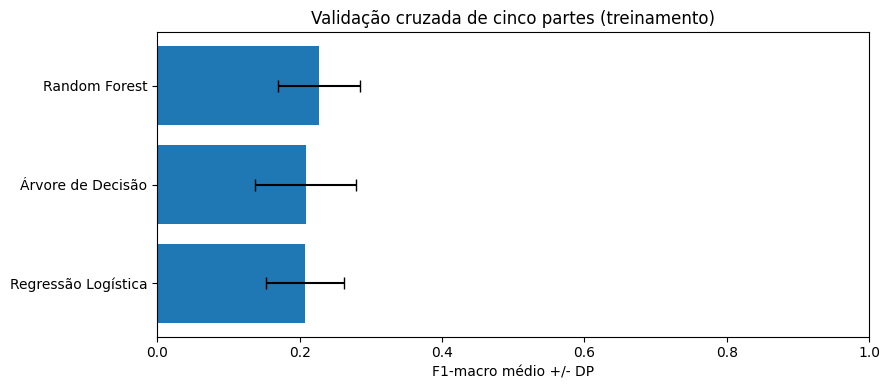

In [8]:
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(resumo_cv['modelo'],resumo_cv['f1_macro_medio'],xerr=resumo_cv['f1_macro_dp'],capsize=4)
ax.invert_yaxis();ax.set(xlim=(0,1),xlabel='F1-macro médio +/- DP',title='Validação cruzada de cinco partes (treinamento)')
fig.tight_layout();plt.show()

## 7. Critério técnico de seleção
O maior F1-macro médio na validação cruzada determina qual classificador é avaliado no teste reservado. A comunicação de aprovação da equipe é separada deste critério computacional.

In [9]:
MODELO_AVALIADO=resumo_cv.loc[0,'modelo']
assert MODELO_AVALIADO in modelos
print('Classificador selecionado tecnicamente:',MODELO_AVALIADO)
print('F1-macro CV:',round(resumo_cv.loc[0,'f1_macro_medio'],6))

Classificador selecionado tecnicamente: Random Forest
F1-macro CV: 0.227408


## 8. Avaliação no conjunto de teste reservado

In [10]:
modelo_final=clone(modelos[MODELO_AVALIADO]);modelo_final.fit(X_treino,y_treino)
previsoes_teste=modelo_final.predict(X_teste)
resultado_f1=f1_score(y_teste,previsoes_teste,average='macro',zero_division=0)
resultado_acc=accuracy_score(y_teste,previsoes_teste)
print('F1-macro (teste):',f'{resultado_f1:.6f}')
print('Acurácia (teste):',f'{resultado_acc:.6f}',f'({int((y_teste.values==previsoes_teste).sum())}/29)')
print(classification_report(y_teste,previsoes_teste,labels=list(nomes_classes),target_names=list(nomes_classes.values()),zero_division=0))

F1-macro (teste): 0.288095
Acurácia (teste): 0.379310 (11/29)
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         2
          DD       0.28      0.71      0.40         7
          DC       0.00      0.00      0.00         5
          CC       0.67      0.50      0.57         4
          CB       0.00      0.00      0.00         2
          BB       0.00      0.00      0.00         3
          BA       0.67      0.67      0.67         3
          AA       0.67      0.67      0.67         3

    accuracy                           0.38        29
   macro avg       0.28      0.32      0.29        29
weighted avg       0.30      0.38      0.31        29



Matriz de confusão - linhas reais, colunas previstas:


,Fail,DD,DC,CC,CB,BB,BA,AA
Fail,0,1,1,0,0,0,0,0
DD,0,5,1,0,0,0,0,1
DC,0,5,0,0,0,0,0,0
CC,0,2,0,2,0,0,0,0
CB,0,1,0,1,0,0,0,0
BB,0,3,0,0,0,0,0,0
BA,0,1,0,0,0,0,2,0
AA,0,0,0,0,0,0,1,2


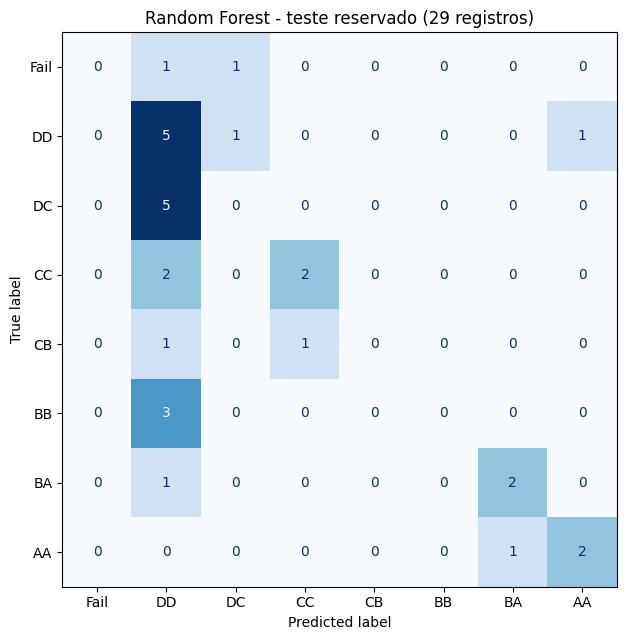

In [11]:
matriz=confusion_matrix(y_teste,previsoes_teste,labels=list(nomes_classes))
print('Matriz de confusão - linhas reais, colunas previstas:')
display(pd.DataFrame(matriz,index=nomes_classes.values(),columns=nomes_classes.values()))
fig,ax=plt.subplots(figsize=(7.4,6.5))
ConfusionMatrixDisplay(confusion_matrix=matriz,display_labels=list(nomes_classes.values())).plot(cmap='Blues',colorbar=False,ax=ax)
ax.set_title('Random Forest - teste reservado (29 registros)');fig.tight_layout();plt.show()

## 9. Conferência automatizada contra o relatório técnico

In [12]:
f1_referencia=0.28809523809523807
acuracia_referencia=11/29
assert abs(resultado_f1-f1_referencia)<1e-12, 'Divergência no F1-macro do teste!'
assert abs(resultado_acc-acuracia_referencia)<1e-12, 'Divergência na acurácia do teste!'
assert np.trace(matriz)==11 and matriz.sum()==29
print('Conferência PASSOU: F1, acurácia, matriz e amostras coincidem com o registro técnico.')

Conferência PASSOU: F1, acurácia, matriz e amostras coincidem com o registro técnico.


## 10. Interpretação e limites
- O Random Forest atingiu F1-macro médio **0,227408** em validação cruzada; esse resultado é baixo e não representa aplicação bem-sucedida no MVP.
- Teste reservado: **F1-macro 0,288095**, **acurácia 37,93% (11/29)**. Quatro classes não tiveram acertos.
- O F1 no treinamento foi **1,000000**, contra F1 baixo na validação. Essa diferença indica possível sobreajuste e falta de generalização.
- O objetivo é **classificação retrospectiva**, sem comprovação de previsão antecipada, causalidade, equidade ou utilidade clínica/educacional real.
- **Autoria:** resultados de reprodução computacional orientada por IA. As decisões e interpretações acadêmicas são responsabilidade dos estudantes.

### Registro de uso da IA
Ferramenta: ChatGPT. Objetivo: verificação técnica, reexecução local, inspeção e organização de evidências. A avaliação acadêmica e a confirmação de entrega são de responsabilidade da equipe. Nenhum dado pessoal sensível foi utilizado.

**Esta execução não atesta execução no Google Colab oficial.**